# Validation Complète Modèle 1 — Segmentation d'instance (YOLOv8-seg) — Maximum de Métriques

Ce notebook exécute la validation complète (`model.val(...)`) sur votre modèle de segmentation entraîné (`best_ep100.pt` / `best.pt`) et extrait **le maximum de métriques Box & Mask ainsi que les graphiques** :
- **Bloc 1** : Configuration des chemins (`MODEL_PATH`, `DATA_YAML`, split `val` ou `test`, paramètres d'évaluation).
- **Bloc 2** : Exécution de `model.val(..., task="segment")` avec génération des courbes et matrices (`plots=True`, `save_json=True`).
- **Bloc 3** : Extraction détaillée de toutes les métriques globales et par classe pour **Box** et **Mask** (Précision, Rappel, F1-score, `mAP50`, `mAP75`, `mAP50-95`, fitness, temps d'inférence, matrice de confusion, métriques par image).
- **Bloc 4** : Affichage des courbes générées (Matrices de confusion Box/Mask, PR-curve, F1-curve, P-curve, R-curve) et export en CSV / JSON.
- **Bloc 5** : Comparaison multi-paliers (`best_ep10.pt` à `best_ep100.pt`) sur le split choisi (`val` ou `test`).

## Bloc 1 — Configuration des chemins et paramètres de validation

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
from ultralytics import YOLO

# 1. Chemin vers votre modèle entraîné du Module 1 (Segmentation YOLOv8-seg)
MODEL_PATH = Path(r"D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers\best_ep100.pt").resolve()

# 2. Chemin vers le fichier data.yaml correspondant au dataset de segmentation
DATA_YAML = Path(r"D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\data.yaml").resolve()

# 3. Split à évaluer ('val' ou 'test')
EVAL_SPLIT = "val"

# 4. Paramètres de validation (cohérents avec l'entraînement : imgsz=640, iou=0.7)
IMG_SIZE = 640
BATCH_SIZE = 8
IOU_THRESHOLD = 0.7
# Laisser CONF_THRESHOLD = None pour le calcul standard mAP (recommandé), ou fixer ex. 0.25 pour matrice opérationnelle
CONF_THRESHOLD = None

OUTPUT_DIR = Path(r"D:\S5\Projet_d_expertise\projet\evaluations").resolve()
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Configuration de validation (Module 1 - Segmentation) :")
print("  - Modèle   :", MODEL_PATH)
print("  - Dataset  :", DATA_YAML)
print("  - Split    :", EVAL_SPLIT)
print("  - Device   :", DEVICE)

Configuration de validation (Module 1 - Segmentation) :
  - Modèle   : D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers\best_ep100.pt
  - Dataset  : D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\data.yaml
  - Split    : val
  - Device   : cpu


## Bloc 2 — Lancement de la validation complète (`model.val`)

In [9]:
# Recherche automatique du dernier modèle de segmentation si le chemin par défaut n'existe pas
if not MODEL_PATH.exists():
    found_models = sorted(
        Path(r"D:\S5\Projet_d_expertise\projet\models").glob("*01_detection_et_segmentation*/**/*.pt"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if found_models:
        MODEL_PATH = found_models[0].resolve()
        print(f"Modèle trouvé automatiquement : {MODEL_PATH}")
    else:
        raise FileNotFoundError(f"Modèle introuvable : {MODEL_PATH}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Fichier data.yaml introuvable : {DATA_YAML}")

model = YOLO(str(MODEL_PATH))
print(f"Tâche du modèle : {model.task} | Classes : {model.names}")

run_eval_name = f"01_detection_et_segmentation_{MODEL_PATH.stem}_{EVAL_SPLIT}"
val_kwargs = dict(
    data=str(DATA_YAML),
    task="segment",
    split=EVAL_SPLIT,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    iou=IOU_THRESHOLD,
    device=DEVICE,
    plots=True,
    save_json=True,
    project=str(OUTPUT_DIR),
    name=run_eval_name,
    exist_ok=True,
)
if CONF_THRESHOLD is not None:
    val_kwargs["conf"] = CONF_THRESHOLD

metrics = model.val(**val_kwargs)
save_dir = Path(metrics.save_dir)
print(f"Validation terminée. Résultats sauvegardés dans : {save_dir}")

Tâche du modèle : segment | Classes : {0: 'cable', 1: 'cable-tie', 2: 'clip', 3: 'connector', 4: 'label'}
Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,259,039 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 56.016.8 MB/s, size: 26.9 KB)
val: Scanning D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 40.8s/it 2:021:3850
                   all         22        106      0.899      0.667      0.753      0.566       0.83      0.661      0.718      0.549
                 cable          3         31          1     0.0551       0.26      0.121      0.654     0.0323        0.1     0.0553
       

## Bloc 3 — Extraction de toutes les métriques Box & Mask (Globales, par classe, par image, vitesse & confusion)

In [10]:
# 1. Dictionnaire brut de toutes les métriques scalaires Ultralytics
results_dict = getattr(metrics, "results_dict", {})
df_global = pd.DataFrame([
    {"Metrique": k, "Valeur": round(float(v), 6)} for k, v in results_dict.items()
])

# 2. Extraction détaillée pour BOX et MASK (spécifique à la segmentation d'instance)
extra_rows = []
for attr in ["box", "seg"]:
    metric_obj = getattr(metrics, attr, None)
    if metric_obj is not None and hasattr(metric_obj, "map"):
        label = "MASK" if attr == "seg" else "BOX"
        p_mean = float(getattr(metric_obj, "mp", np.nan))
        r_mean = float(getattr(metric_obj, "mr", np.nan))
        f1_mean = (2 * p_mean * r_mean / (p_mean + r_mean)) if (p_mean + r_mean) > 0 else 0.0
        extra_rows.extend([
            {"Metrique": f"{label}/Precision_moyenne (mp)", "Valeur": round(p_mean, 6)},
            {"Metrique": f"{label}/Recall_moyen (mr)", "Valeur": round(r_mean, 6)},
            {"Metrique": f"{label}/F1_moyen", "Valeur": round(f1_mean, 6)},
            {"Metrique": f"{label}/mAP50", "Valeur": round(float(getattr(metric_obj, "map50", np.nan)), 6)},
            {"Metrique": f"{label}/mAP75", "Valeur": round(float(getattr(metric_obj, "map75", np.nan)), 6)},
            {"Metrique": f"{label}/mAP50-95", "Valeur": round(float(getattr(metric_obj, "map", np.nan)), 6)},
        ])

# 3. Vitesse d'exécution (ms / image)
speed = getattr(metrics, "speed", {})
for sp_k, sp_v in speed.items():
    extra_rows.append({"Metrique": f"Speed_{sp_k}_ms", "Valeur": round(float(sp_v), 3)})
if speed:
    total_ms = sum(float(v) for v in speed.values())
    extra_rows.append({"Metrique": "Speed_total_ms", "Valeur": round(total_ms, 3)})
    if total_ms > 0:
        extra_rows.append({"Metrique": "FPS_estime", "Valeur": round(1000.0 / total_ms, 2)})

df_global = pd.concat([df_global, pd.DataFrame(extra_rows)], ignore_index=True).drop_duplicates(subset=["Metrique"])
print("=== MÉTRIQUES GLOBALES (BOX & MASK) ===")
display(df_global)

# 4. Métriques détaillées PAR CLASSE (comparaison côte à côte Box vs Mask)
box_obj = getattr(metrics, "box", None)
seg_obj = getattr(metrics, "seg", None)

per_class_rows = []
ref_obj = seg_obj if (seg_obj is not None and hasattr(seg_obj, "ap_class_index")) else box_obj
if ref_obj is not None and hasattr(ref_obj, "ap_class_index"):
    class_indices = ref_obj.ap_class_index
    for idx_pos, cid in enumerate(class_indices):
        cid_int = int(cid)
        cname = model.names.get(cid_int, str(cid_int))

        # Métriques Box
        box_p = float(box_obj.p[idx_pos]) if (box_obj is not None and idx_pos < len(box_obj.p)) else np.nan
        box_r = float(box_obj.r[idx_pos]) if (box_obj is not None and idx_pos < len(box_obj.r)) else np.nan
        box_f1 = float(box_obj.f1[idx_pos]) if (box_obj is not None and idx_pos < len(box_obj.f1)) else (
            (2 * box_p * box_r / (box_p + box_r)) if (box_p + box_r) > 0 else 0.0
        )
        box_ap50 = float(box_obj.ap50[idx_pos]) if (box_obj is not None and idx_pos < len(box_obj.ap50)) else np.nan
        box_ap = float(box_obj.ap[idx_pos]) if (box_obj is not None and idx_pos < len(box_obj.ap)) else np.nan

        # Métriques Mask (Segmentation)
        mask_p = float(seg_obj.p[idx_pos]) if (seg_obj is not None and idx_pos < len(seg_obj.p)) else np.nan
        mask_r = float(seg_obj.r[idx_pos]) if (seg_obj is not None and idx_pos < len(seg_obj.r)) else np.nan
        mask_f1 = float(seg_obj.f1[idx_pos]) if (seg_obj is not None and idx_pos < len(seg_obj.f1)) else (
            (2 * mask_p * mask_r / (mask_p + mask_r)) if (mask_p + mask_r) > 0 else 0.0
        )
        mask_ap50 = float(seg_obj.ap50[idx_pos]) if (seg_obj is not None and idx_pos < len(seg_obj.ap50)) else np.nan
        mask_ap = float(seg_obj.ap[idx_pos]) if (seg_obj is not None and idx_pos < len(seg_obj.ap)) else np.nan

        per_class_rows.append({
            "class_id": cid_int,
            "class_name": cname,
            "Box_P": round(box_p, 4),
            "Box_R": round(box_r, 4),
            "Box_F1": round(box_f1, 4),
            "Box_AP50": round(box_ap50, 4),
            "Box_AP50_95": round(box_ap, 4),
            "Mask_P": round(mask_p, 4),
            "Mask_R": round(mask_r, 4),
            "Mask_F1": round(mask_f1, 4),
            "Mask_AP50": round(mask_ap50, 4),
            "Mask_AP50_95": round(mask_ap, 4),
        })

df_per_class = pd.DataFrame(per_class_rows)
print("\n=== MÉTRIQUES PAR CLASSE (BOX & MASK) ===")
display(df_per_class)

# 5. Matrice de confusion sous forme de tableau
df_cm = None
if getattr(metrics, "confusion_matrix", None) is not None:
    cm_mat = metrics.confusion_matrix.matrix
    labels_cm = [model.names[i] for i in sorted(model.names.keys())] + ["background"]
    if cm_mat.shape[0] == len(labels_cm):
        df_cm = pd.DataFrame(cm_mat.astype(int), index=[f"Pred_{l}" for l in labels_cm], columns=[f"True_{l}" for l in labels_cm])
    else:
        df_cm = pd.DataFrame(cm_mat.astype(int))
    print("\n=== MATRICE DE CONFUSION ===")
    display(df_cm)

# 6. Métriques par image (si disponibles dans cette version d'Ultralytics)
df_per_image = None
img_metrics = getattr(metrics, "image_metrics", None)
if isinstance(img_metrics, dict) and len(img_metrics) > 0:
    df_per_image = pd.DataFrame.from_dict(img_metrics, orient="index").reset_index().rename(columns={"index": "image"})
    print("\n=== MÉTRIQUES PAR IMAGE (aperçu) ===")
    display(df_per_image.head(20))

=== MÉTRIQUES GLOBALES (BOX & MASK) ===


,Metrique,Valeur
0,metrics/precision(B),0.899039
1,metrics/recall(B),0.667423
2,metrics/mAP50(B),0.753234
3,metrics/mAP50-95(B),0.565954
4,metrics/precision(M),0.829781
5,metrics/recall(M),0.660603
6,metrics/mAP50(M),0.718011
7,metrics/mAP50-95(M),0.548548
8,fitness,1.114502
9,BOX/Precision_moyenne (mp),0.899039



=== MÉTRIQUES PAR CLASSE (BOX & MASK) ===


,class_id,class_name,Box_P,Box_R,Box_F1,Box_AP50,Box_AP50_95,Mask_P,Mask_R,Mask_F1,Mask_AP50,Mask_AP50_95
0,0,cable,1.0000,0.0551,0.1044,0.2597,0.1206,0.6543,0.0323,0.0615,0.1003,0.0553
1,1,cable-tie,1.0000,0.8338,0.9094,0.9950,0.7959,1.0000,0.8303,0.9073,0.9950,0.7960
2,2,clip,0.7906,0.7625,0.7763,0.6899,0.4931,0.7888,0.7553,0.7717,0.6899,0.4071
3,3,connector,0.8144,0.6857,0.7445,0.8266,0.6862,0.8143,0.6851,0.7441,0.8098,0.6390
4,4,label,0.8902,1.0000,0.9419,0.9950,0.7340,0.8915,1.0000,0.9426,0.9950,0.8454



=== MATRICE DE CONFUSION ===


,True_cable,True_cable-tie,True_clip,True_connector,True_label,True_background
Pred_cable,3,0,0,0,0,0
Pred_cable-tie,0,2,0,0,0,1
Pred_clip,0,0,4,0,0,8
Pred_connector,0,0,0,52,0,18
Pred_label,0,0,0,0,4,2
Pred_background,28,0,1,12,0,0


## Bloc 4 — Visualisation des courbes de validation (Box & Mask) & Export des rapports

Tous les tableaux CSV/JSON ont été exportés dans : D:\S5\Projet_d_expertise\projet\evaluations\01_detection_et_segmentation_best_ep100_val


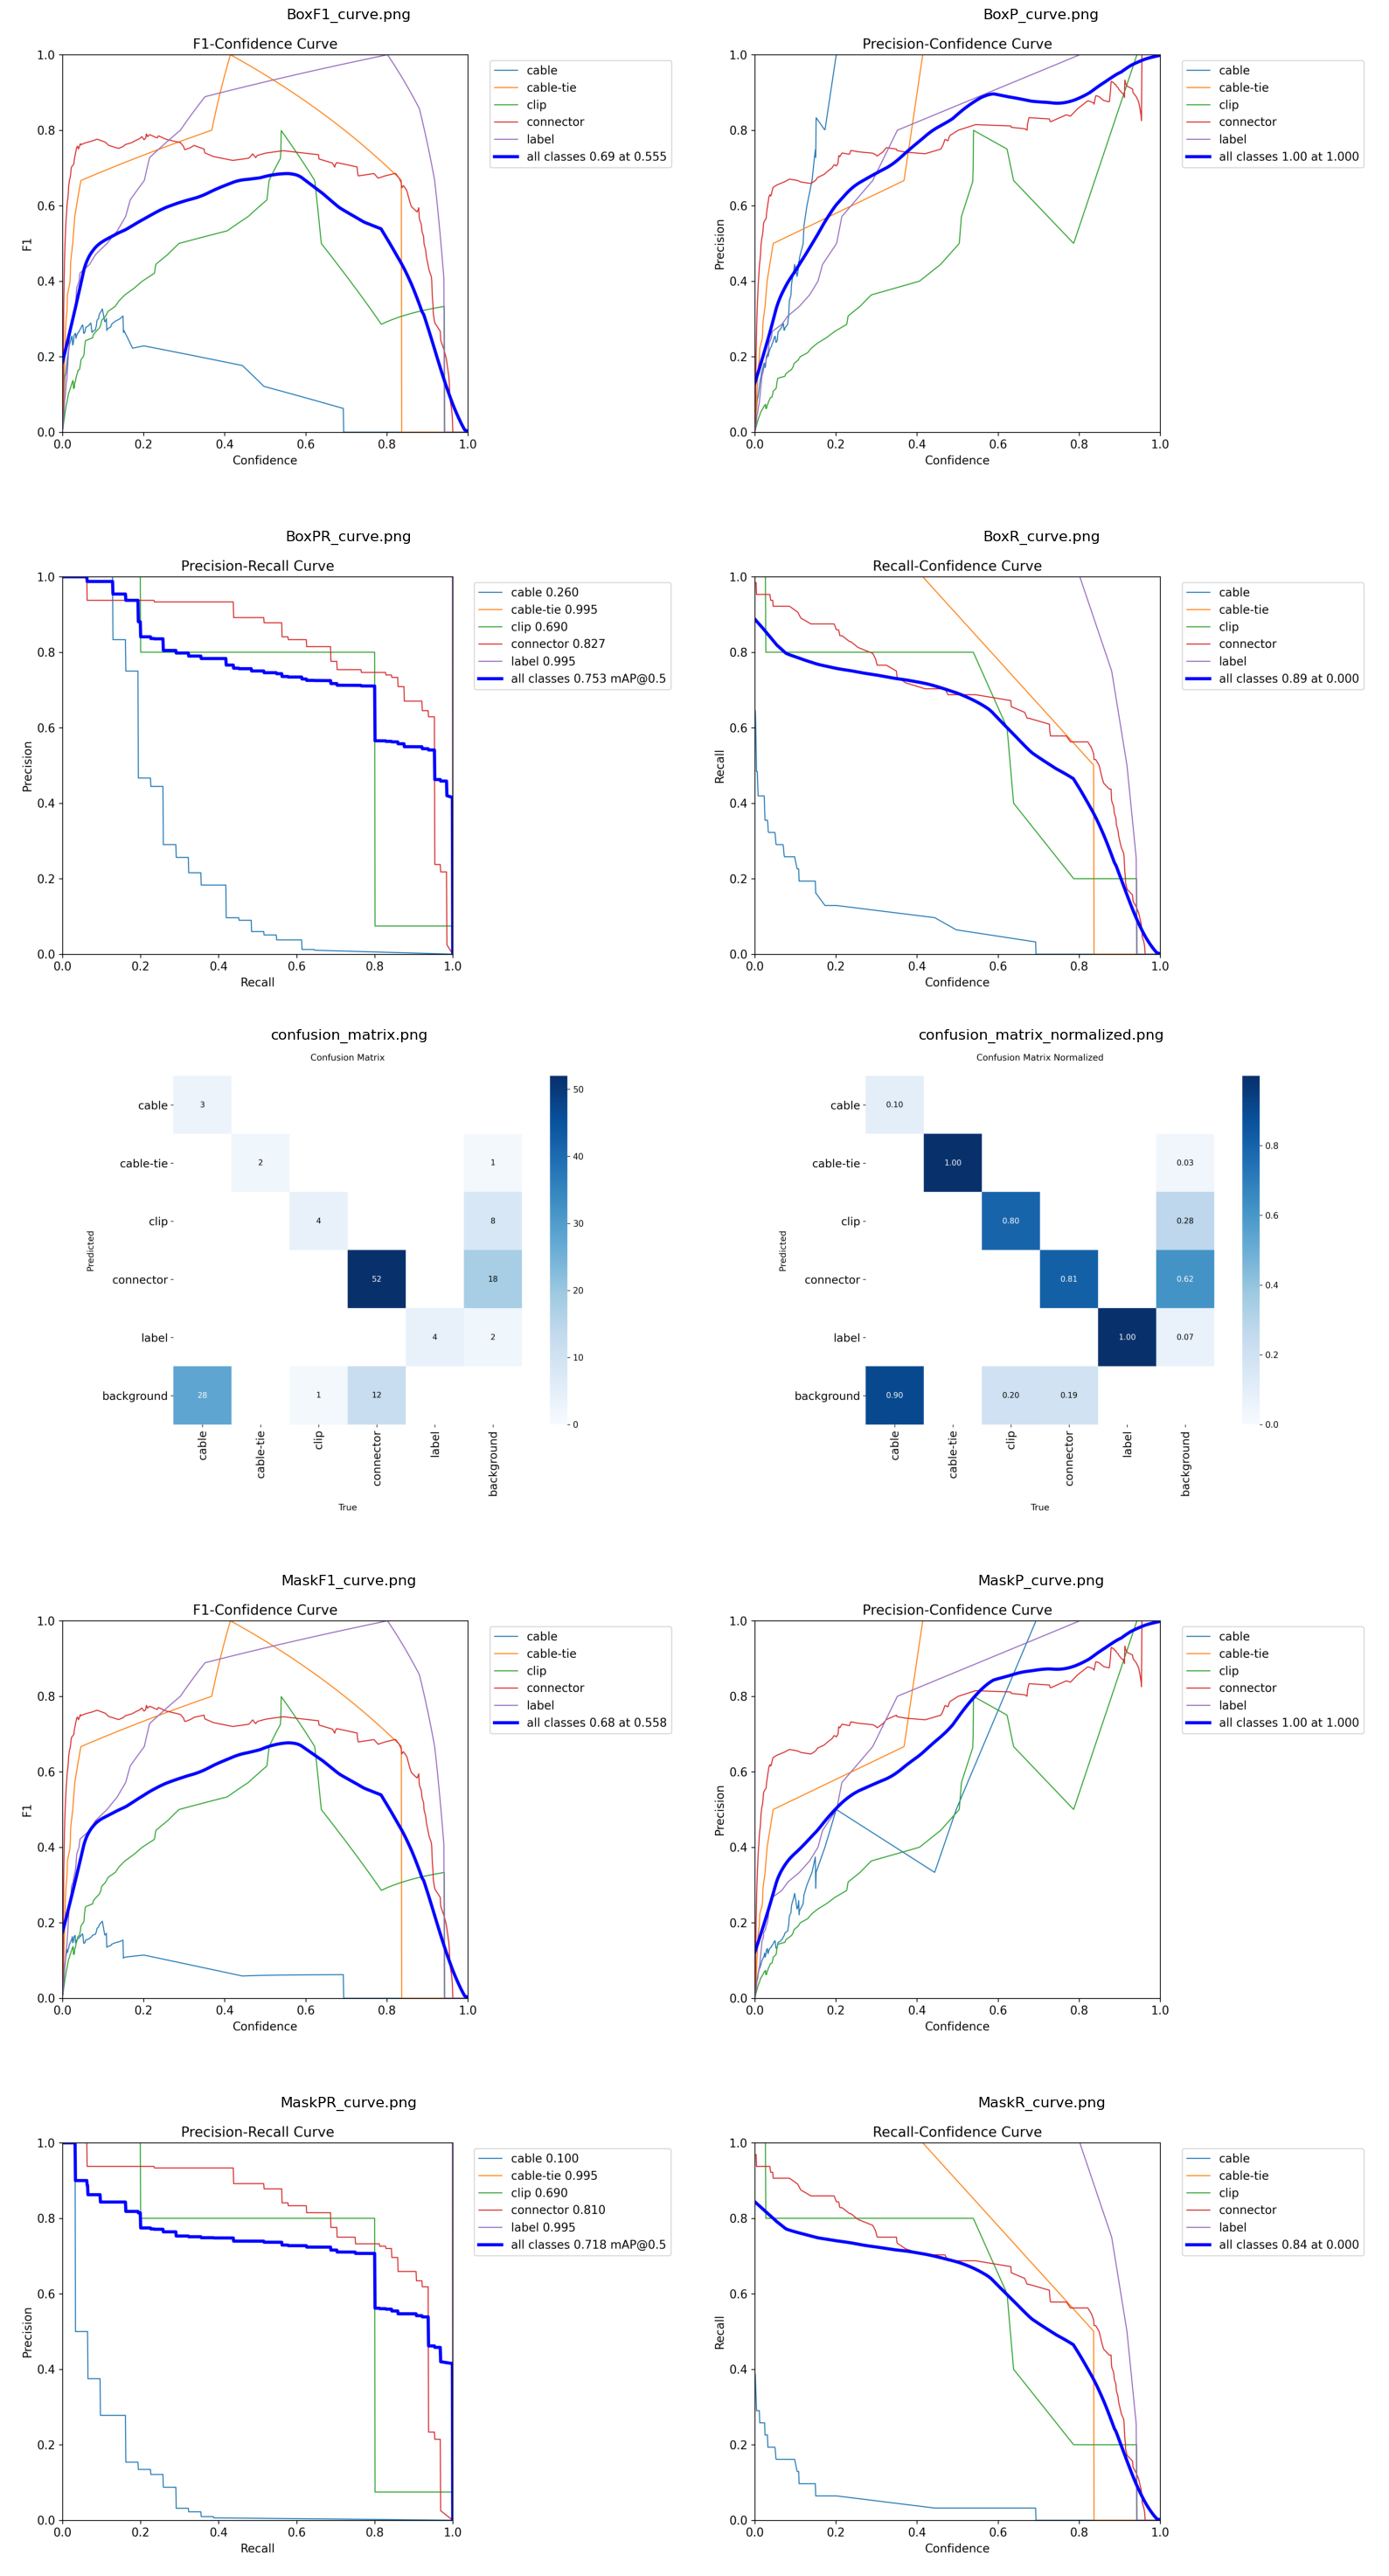

In [11]:
# 1. Export CSV et JSON complets
df_global.to_csv(save_dir / "metrics_globales.csv", index=False, encoding="utf-8-sig")
if not df_per_class.empty:
    df_per_class.to_csv(save_dir / "metrics_par_classe.csv", index=False, encoding="utf-8-sig")
if df_cm is not None:
    df_cm.to_csv(save_dir / "confusion_matrix.csv", encoding="utf-8-sig")
if df_per_image is not None:
    df_per_image.to_csv(save_dir / "metrics_par_image.csv", index=False, encoding="utf-8-sig")

# Export natif Ultralytics (CSV / JSON) si disponible
if hasattr(metrics, "to_csv"):
    (save_dir / "ultralytics_summary.csv").write_text(metrics.to_csv(), encoding="utf-8")
if hasattr(metrics, "to_json"):
    (save_dir / "ultralytics_summary.json").write_text(metrics.to_json(), encoding="utf-8")

print(f"Tous les tableaux CSV/JSON ont été exportés dans : {save_dir}")

# 2. Affichage des courbes et graphiques générés par Ultralytics (Box_* et Mask_*)
plot_files = sorted(save_dir.glob("*.png"))
if plot_files:
    n_plots = len(plot_files)
    cols = 2
    rows = (n_plots + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6 * rows))
    axes = np.array(axes).reshape(-1)
    for i, img_p in enumerate(plot_files):
        im = cv2.imread(str(img_p))
        axes[i].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        axes[i].set_title(img_p.name)
        axes[i].axis("off")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune image .png trouvée dans", save_dir)

## Bloc 5 — (Optionnel) Benchmark des paliers (`best_ep10.pt` à `best_ep100.pt`)

In [12]:
CHECKPOINTS_DIR = Path(r"D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers").resolve()

if CHECKPOINTS_DIR.exists():
    ckpt_files = sorted(
        CHECKPOINTS_DIR.glob("best_ep*.pt"),
        key=lambda p: int("".join(filter(str.isdigit, p.stem)) or 0),
    )
    benchmark_rows = []
    for ckpt in ckpt_files:
        m_ckpt = YOLO(str(ckpt))
        res = m_ckpt.val(
            data=str(DATA_YAML),
            task="segment",
            split=EVAL_SPLIT,
            imgsz=IMG_SIZE,
            batch=BATCH_SIZE,
            iou=IOU_THRESHOLD,
            device=DEVICE,
            plots=False,
            verbose=False,
        )
        benchmark_rows.append({
            "Checkpoint": ckpt.name,
            "Box_P": round(float(res.box.mp), 4),
            "Box_R": round(float(res.box.mr), 4),
            "Box_mAP50": round(float(res.box.map50), 4),
            "Box_mAP50_95": round(float(res.box.map), 4),
            "Mask_P": round(float(res.seg.mp), 4),
            "Mask_R": round(float(res.seg.mr), 4),
            "Mask_mAP50": round(float(res.seg.map50), 4),
            "Mask_mAP50_95": round(float(res.seg.map), 4),
        })

    if benchmark_rows:
        df_bench = pd.DataFrame(benchmark_rows)
        df_bench.to_csv(save_dir / f"benchmark_paliers_{EVAL_SPLIT}.csv", index=False, encoding="utf-8-sig")
        print(f"=== COMPARAISON DES PALIERS ({EVAL_SPLIT}) ===")
        display(df_bench)
else:
    print(f"Dossier des paliers non trouvé : {CHECKPOINTS_DIR}")

Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,259,039 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access  (ping: 0.10.1 ms, read: 53.224.0 MB/s, size: 31.0 KB)
val: Scanning D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.1s/it 9.3s6.5s0s
                   all         22        106      0.776       0.51      0.596      0.469      0.723      0.501      0.579       0.45
Speed: 2.4ms preprocess, 305.1ms inference, 0.0ms loss, 76.5ms postprocess per image
Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,259,039 parameters, 0 gradients, 1

,Checkpoint,Box_P,Box_R,Box_mAP50,Box_mAP50_95,Mask_P,Mask_R,Mask_mAP50,Mask_mAP50_95
0,best_ep10.pt,0.7756,0.5098,0.5959,0.4689,0.7228,0.5005,0.5785,0.4504
1,best_ep20.pt,0.8488,0.5500,0.6440,0.5323,0.8457,0.5469,0.6151,0.4916
2,best_ep30.pt,0.8713,0.5181,0.6671,0.4682,0.8212,0.5069,0.5816,0.4544
3,best_ep40.pt,0.8389,0.5930,0.6637,0.5127,0.8209,0.5626,0.6654,0.4777
4,best_ep50.pt,0.7284,0.5370,0.6259,0.5076,0.7227,0.5335,0.5999,0.4814
5,best_ep60.pt,0.6425,0.6650,0.7152,0.5760,0.6186,0.6554,0.6907,0.5158
6,best_ep70.pt,0.6314,0.6214,0.6850,0.5371,0.5600,0.6056,0.6540,0.4835
7,best_ep80.pt,0.7276,0.7117,0.7229,0.5696,0.6422,0.7032,0.7163,0.5095
8,best_ep90.pt,0.5465,0.6425,0.7038,0.5523,0.9378,0.4969,0.6395,0.4744
9,best_ep100.pt,0.8990,0.6674,0.7532,0.5660,0.8298,0.6606,0.7179,0.5499
